# Customer Intelligence Platform for a Digital Bank

## Customer Analysis

---

## Business Objective

The objective of this phase is to develop a comprehensive understanding of the bank's customer base by analyzing demographic characteristics, income profiles, acquisition channels, product adoption, and customer engagement.

The insights generated during this analysis will help identify key customer segments, understand customer behavior, and support future recommendations aimed at improving customer acquisition, engagement, and retention.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", None)

customers = pd.read_csv("../data/customers_clean.csv")
transactions = pd.read_csv("../data/transactions_clean.csv")

## Customer Overview
Now we answer the first business question.
### Who are our customers?

Before plotting anything, let's calculate the KPIs.

In [2]:
customer_overview = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Average Age",
        "Median Age",
        "Average Products per Customer",
        "Average Monthly Transactions",
        "Average Transaction Value",
        "Average Satisfaction Score",
        "Average NPS"
    ],
    "Value": [
        len(customers),
        int(customers["age"].mean()),
        customers["age"].median(),
        round(customers["active_products"].mean(), 2),
        round(customers["monthly_transaction_count"].mean(), 2),
        round(customers["average_transaction_value"].mean(), 2),
        round(customers["satisfaction_score"].mean(), 2),
        round(customers["nps_score"].mean(), 2)
    ]
})

customer_overview.head(10)

,Metric,Value
0,Total Customers,48723.00
1,Average Age,44.00
2,Median Age,45.00
3,Average Products per Customer,2.10
4,Average Monthly Transactions,5.77
5,Average Transaction Value,3564851.69
6,Average Satisfaction Score,4.16
7,Average NPS,-26.76


## Executive Summary

The customer dataset contains **48,723 customers**, providing a substantial foundation for understanding the bank's customer base and supporting reliable customer analytics.

Customers have an average age of **44 years**, with a median age of **45 years**, indicating that the bank primarily serves mature working-age adults. This suggests opportunities to tailor products and services toward customers who are likely to have established financial responsibilities and long-term banking needs.

On average, customers hold **2.10 banking products**, indicating moderate product adoption across the customer base. This presents potential opportunities for cross-selling additional financial products to existing customers.

Customer activity averages **5.77 transactions per month**, providing an initial indication of regular engagement with the bank's services. The average transaction value will be interpreted after confirming the transaction currency and unit of measurement.

Overall customer satisfaction averages **4.16**, suggesting generally positive customer experiences. However, the average Net Promoter Score (NPS) is **-26.76**, which establishes an important baseline for further investigation during the customer experience analysis.

## Age Distribution
#### Business Question
What is the age profile of the bank's customers?

In [3]:
customers["age"].describe()

count    48723.000000
mean        44.544938
std         12.276843
min         29.000000
25%         30.000000
50%         45.000000
75%         59.000000
max         60.000000
Name: age, dtype: float64

In [4]:
age_summary = pd.DataFrame({
    "Metric": [
        "Minimum Age",
        "Maximum Age",
        "Average Age",
        "Median Age",
        "Standard Deviation"
    ],
    "Value": [
        customers["age"].min(),
        customers["age"].max(),
        round(customers["age"].mean(), 2),
        customers["age"].median(),
        round(customers["age"].std(), 2)
    ]
})

age_summary

,Metric,Value
0,Minimum Age,29.00
1,Maximum Age,60.00
2,Average Age,44.54
3,Median Age,45.00
4,Standard Deviation,12.28


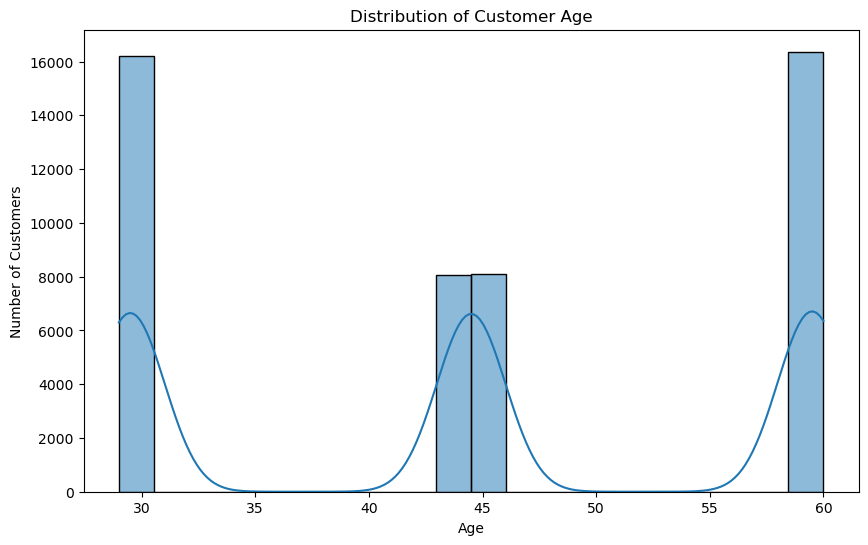

In [5]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=customers,
    x="age",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

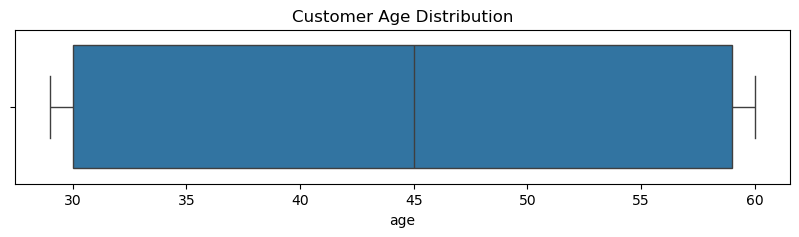

In [6]:
plt.figure(figsize=(10,2))

sns.boxplot(
    x=customers["age"]
)

plt.title("Customer Age Distribution")

plt.show()

In [7]:
bins = [18, 25, 35, 45, 55, 65, 100]

labels = [
    "18–25",
    "26–35",
    "36–45",
    "46–55",
    "56–65",
    "65+"
]

customers["age_group"] = pd.cut(
    customers["age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [8]:
age_group_counts = (
    customers["age_group"]
    .value_counts()
    .sort_index()
)

age_group_counts

age_group
18–25        0
26–35    16219
36–45    16139
46–55        0
56–65    16365
65+          0
Name: count, dtype: int64

In [9]:
age_group_percent = (
    customers["age_group"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
).round(1)

age_group_percent

age_group
18–25     0.0
26–35    33.3
36–45    33.1
46–55     0.0
56–65    33.6
65+       0.0
Name: proportion, dtype: float64

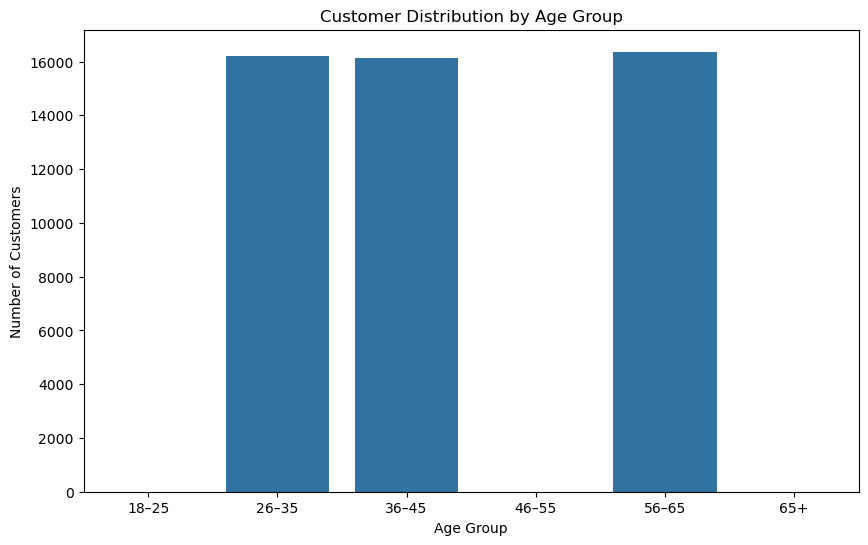

In [10]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=customers,
    x="age_group",
    order=labels
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.show()

In [11]:
customers['age'].describe()
customers["age"].value_counts().sort_index()
customers["age"].unique()

array([44, 45, 59, 60, 29, 30])

In [12]:
customers["age_segment"] = customers["age"].replace({
    29: "Young Professionals (29–30)",
    30: "Young Professionals (29–30)",
    44: "Mid-Career Adults (44–45)",
    45: "Mid-Career Adults (44–45)",
    59: "Pre-Retirement Adults (59–60)",
    60: "Pre-Retirement Adults (59–60)"
})

In [13]:
age_segment = (
    customers["age_segment"]
    .value_counts()
)

age_segment

age_segment
Pre-Retirement Adults (59–60)    16365
Young Professionals (29–30)      16219
Mid-Career Adults (44–45)        16139
Name: count, dtype: int64

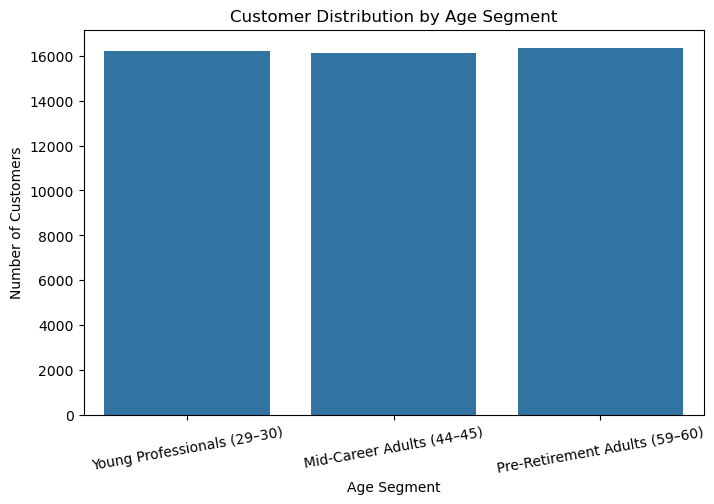

In [14]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=customers,
    x="age_segment",
    order=[
        "Young Professionals (29–30)",
        "Mid-Career Adults (44–45)",
        "Pre-Retirement Adults (59–60)"
    ]
)

plt.title("Customer Distribution by Age Segment")
plt.xlabel("Age Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=10)

plt.show()

### Interpretation

The customer dataset is evenly distributed across three age segments: Young Professionals (29–30 years), Mid-Career Adults (44–45 years), and Pre-Retirement Adults (59–60 years), with each group representing approximately one-third of the customer base.

This balanced distribution suggests that the dataset was intentionally designed to facilitate comparative analysis across different stages of the customer lifecycle rather than to reflect the exact demographic composition of a real banking population. Consequently, the age segments provide an excellent foundation for exploring differences in product adoption, digital engagement, transaction behaviour, and customer satisfaction.

### Business Implication

Rather than using age to estimate the demographic profile of the bank's entire customer base, this variable should be treated as a segmentation feature. Subsequent analyses will compare customer behaviour across these three life stages to identify differences in banking needs, product usage, and engagement.

Now, let's check whether customers at different life stages own different numbers of banking products?

In [15]:
active_products_by_age = (
    customers
    .groupby("age_segment", observed=True)["active_products"]
    .agg(
        Average_Products="mean",
        Median_Products="median",
        Minimum="min",
        Maximum="max",
        Customers="count"
    )
    .round(2)
)

active_products_by_age

,Average_Products,Median_Products,Minimum,Maximum,Customers
age_segment,,,,,
Mid-Career Adults (44–45),2.09,2.0,1,5,16139
Pre-Retirement Adults (59–60),2.11,2.0,1,5,16365
Young Professionals (29–30),2.09,2.0,1,5,16219


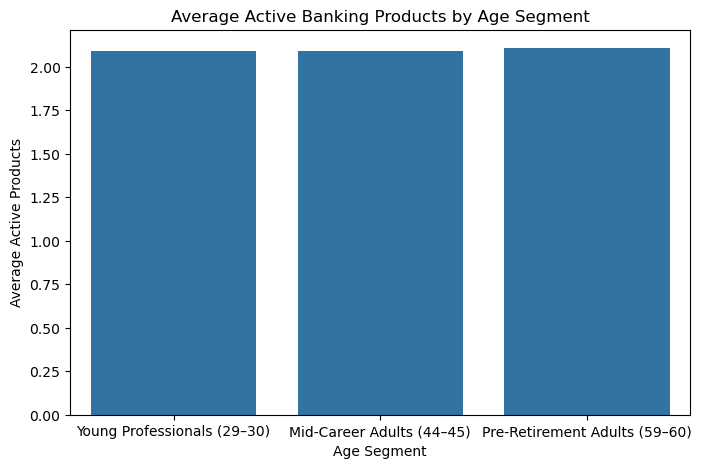

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=customers,
    x="age_segment",
    y="active_products",
    estimator="mean",
    errorbar=None,
    order=[
        "Young Professionals (29–30)",
        "Mid-Career Adults (44–45)",
        "Pre-Retirement Adults (59–60)"
    ]
)

plt.title("Average Active Banking Products by Age Segment")

plt.xlabel("Age Segment")

plt.ylabel("Average Active Products")

plt.show()

### Interpretation

The average number of active banking products is remarkably consistent across all three age segments, ranging from 2.09 to 2.11 products per customer.

This suggests that product adoption does not vary substantially across customer life stages within this dataset. Regardless of age segment, customers maintain a similar number of banking products, indicating that age alone is not a strong differentiator of product ownership.

### Business Question 2
Does income level influence the number of active banking products?

In [17]:
customers["income_bracket"].value_counts().sort_index()

income_bracket
High         12180
Low          14617
Medium       19489
Very High     2437
Name: count, dtype: int64

In [18]:
products_by_income = (
    customers
    .groupby("income_bracket", observed=True)["active_products"]
    .agg(
        Average_Products="mean",
        Median_Products="median",
        Minimum="min",
        Maximum="max",
        Customers="count"
    )
    .round(2)
)

products_by_income

,Average_Products,Median_Products,Minimum,Maximum,Customers
income_bracket,,,,,
High,2.09,2.0,1,5,12180
Low,2.10,2.0,1,5,14617
Medium,2.10,2.0,1,5,19489
Very High,2.08,2.0,1,5,2437


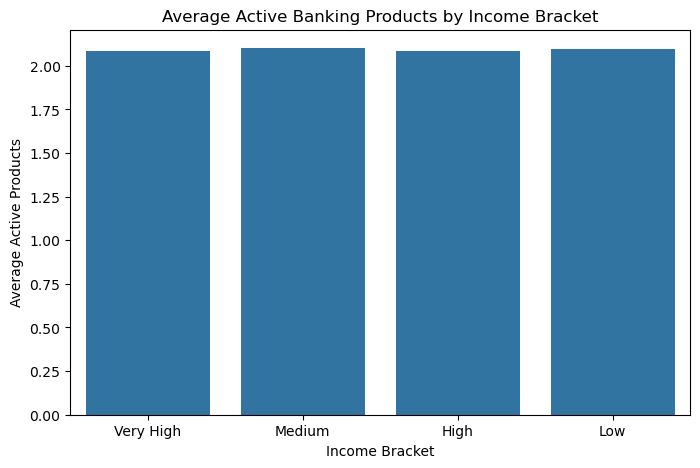

In [19]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=customers,
    x="income_bracket",
    y="active_products",
    estimator="mean",
    errorbar=None
)

plt.title("Average Active Banking Products by Income Bracket")
plt.xlabel("Income Bracket")
plt.ylabel("Average Active Products")

plt.show()

### Key Findings

The customer base is relatively balanced across the three age segments represented in the dataset. Similarly, product ownership remains consistent across age and income groups, suggesting that demographic characteristics alone are not strong indicators of customer engagement or product adoption.

While the customer profile provides useful context regarding the bank's clientele, it offers limited explanatory power for understanding customer behaviour. Consequently, subsequent analyses will focus on behavioural variables such as digital engagement, transaction activity, and product usage, which are expected to provide more actionable business insights.

### Customer Engagement
Business Question:
Does digital engagement influence product adoption?

In [22]:
#Do customers who log in more frequently own more banking products?
customers[["app_logins_frequency",
    "active_products"]].corr()

,app_logins_frequency,active_products
app_logins_frequency,1.000000,-0.000007
active_products,-0.000007,1.000000


In [23]:
#lets test out something here before we proceed
numerical_columns = customers.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numerical_columns

['customer_id',
 'age',
 'household_size',
 'active_products',
 'app_logins_frequency',
 'feature_usage_diversity',
 'credit_utilization_ratio',
 'international_transactions',
 'failed_transactions',
 'tx_count',
 'avg_tx_value',
 'total_tx_volume',
 'base_satisfaction',
 'tx_satisfaction',
 'product_satisfaction',
 'satisfaction_score',
 'nps_score',
 'support_tickets_count',
 'resolved_tickets_ratio',
 'app_store_rating',
 'monthly_transaction_count',
 'average_transaction_value',
 'total_transaction_volume',
 'transaction_frequency',
 'weekend_transaction_ratio',
 'avg_daily_transactions',
 'customer_tenure',
 'churn_probability',
 'customer_lifetime_value']

In [24]:
numerical_columns.remove("customer_id")

In [25]:
corr_matrix = customers[numerical_columns].corr()

In [26]:
corr_matrix

,age,household_size,active_products,app_logins_frequency,feature_usage_diversity,credit_utilization_ratio,international_transactions,failed_transactions,tx_count,avg_tx_value,total_tx_volume,base_satisfaction,tx_satisfaction,product_satisfaction,satisfaction_score,nps_score,support_tickets_count,resolved_tickets_ratio,app_store_rating,monthly_transaction_count,average_transaction_value,total_transaction_volume,transaction_frequency,weekend_transaction_ratio,avg_daily_transactions,customer_tenure,churn_probability,customer_lifetime_value
age,1.000000,-0.001890,0.005667,0.005815,0.261997,-0.000063,-0.005083,-0.003209,0.004682,-0.003309,0.001857,0.004964,-0.004153,0.388424,0.046510,0.044728,0.007501,0.000793,-0.003891,-0.000200,-0.002571,-0.003026,-0.000227,0.001469,-0.000227,-0.001673,0.211312,-0.004568
household_size,-0.001890,1.000000,-0.005885,0.002175,-0.001342,0.000144,-0.003283,-0.003548,0.004069,-0.000284,0.003666,0.005827,0.003097,0.002174,0.007323,0.006807,-0.010823,-0.004598,-0.000222,-0.006026,0.002442,-0.006145,-0.006038,0.005838,-0.006038,-0.000359,0.003366,0.002855
active_products,0.005667,-0.005885,1.000000,-0.000007,0.003873,-0.000276,-0.002140,0.003318,-0.002946,-0.003079,-0.006610,0.000906,0.001986,0.006143,0.001023,0.000819,0.004616,0.005933,0.006185,-0.001043,-0.001535,0.001173,-0.001085,0.003859,-0.001085,-0.002404,-0.875972,0.001241
app_logins_frequency,0.005815,0.002175,-0.000007,1.000000,-0.010342,0.003421,0.005494,0.003302,-0.001754,0.005827,0.001394,-0.009927,-0.004684,-0.004618,-0.011268,-0.008678,-0.000481,0.005953,-0.007251,-0.004400,-0.003721,-0.004254,-0.004349,-0.000184,-0.004349,0.003276,-0.256466,-0.001776
feature_usage_diversity,0.261997,-0.001342,0.003873,-0.010342,1.000000,-0.003338,0.001191,0.005893,-0.008989,-0.002809,-0.007082,-0.006159,-0.009776,0.668398,0.063322,0.058623,-0.000873,-0.002211,-0.003890,-0.003349,0.007427,-0.002624,-0.003341,-0.000313,-0.003341,0.009062,0.028740,-0.004867
credit_utilization_ratio,-0.000063,0.000144,-0.000276,0.003421,-0.003338,1.000000,0.001020,-0.001283,-0.003498,-0.004369,0.000398,0.009907,0.006375,-0.003438,0.008035,0.006562,-0.000588,-0.000389,-0.004654,0.001241,0.004088,-0.000425,0.001291,0.001461,0.001291,-0.001881,-0.002246,-0.000303
international_transactions,-0.005083,-0.003283,-0.002140,0.005494,0.001191,0.001020,1.000000,0.001378,-0.000888,-0.002613,-0.000878,0.002630,0.006510,-0.003385,0.002131,0.004546,-0.011370,-0.007963,0.002089,-0.003260,-0.003824,-0.001081,-0.003270,0.003882,-0.003270,-0.000139,-0.000297,0.002581
failed_transactions,-0.003209,-0.003548,0.003318,0.003302,0.005893,-0.001283,0.001378,1.000000,-0.003514,0.000844,-0.001400,0.003168,-0.005168,0.003499,0.000451,0.000336,0.007524,0.004616,0.002502,0.008268,-0.004428,0.008011,0.008277,0.003272,0.008277,-0.001148,-0.003671,0.000365
tx_count,0.004682,0.004069,-0.002946,-0.001754,-0.008989,-0.003498,-0.000888,-0.003514,1.000000,0.010868,0.812243,-0.006229,0.253043,-0.000575,0.017435,0.014639,-0.004453,-0.004580,0.000873,-0.002215,-0.004406,-0.001268,-0.002203,0.002280,-0.002203,-0.006398,-0.028062,0.163954
avg_tx_value,-0.003309,-0.000284,-0.003079,0.005827,-0.002809,-0.004369,-0.002613,0.000844,0.010868,1.000000,0.051497,-0.001998,0.000144,-0.003888,-0.002364,-0.002095,0.004599,0.005480,-0.007445,-0.001852,0.001976,-0.000387,-0.001843,-0.003521,-0.001843,-0.011416,0.000435,0.343133


In [27]:
corr_pairs = (
    corr_matrix
    .where(~np.triu(np.ones(corr_matrix.shape), k=0).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Variable 1",
    "Variable 2",
    "Correlation"
]

In [28]:
corr_pairs = corr_pairs.reindex(
    corr_pairs["Correlation"]
    .abs()
    .sort_values(ascending=False)
    .index
)

corr_pairs.head(30)

,Variable 1,Variable 2,Correlation
298,avg_daily_transactions,transaction_frequency,1.000000
295,avg_daily_transactions,monthly_transaction_count,0.999983
250,transaction_frequency,monthly_transaction_count,0.999983
119,nps_score,satisfaction_score,0.916708
327,churn_probability,active_products,-0.875972
102,satisfaction_score,base_satisfaction,0.855531
229,total_transaction_volume,monthly_transaction_count,0.812461
297,avg_daily_transactions,total_transaction_volume,0.812309
252,transaction_frequency,total_transaction_volume,0.812309
53,total_tx_volume,tx_count,0.812243
